# What the engine misses at its shipped values: the priors of a Bayesian calibration, the engine's response to them and the shape of its error

**Question:** What do the engine's shipped values leave unexplained on the ten HP500 surveys, which of its eight fitted scalars can move the answer at all, and what form of error does a Bayesian calibration have to add around it?

- **Level:** 1, fundamentals
- **Prerequisites:** notebook 02 of topic 05 and notebooks 01 and 02 of topic 06
- **Reading time:** about 40 minutes

## Objectives

By the end of this notebook you can:

- say which eight scalars of the crusher engine a Bayesian calibration treats as unknown, with the value each one ships with and the width of its prior;
- run the engine at a set of scalar values other than the shipped ones, and measure which scalar moves the throughput and which moves the power;
- draw from the priors, run the engine at every draw, and say whether the measured values fall inside the resulting band before any survey has been used;
- describe the part of the engine's error that is a function of the setting and the feed size, which is the part a discrepancy term is for.

## Setup

Numpy and matplotlib; the engine and the calibration's definitions come from the pipeline.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

The imports bring the survey reader, the engine with its operating-point constructor for a survey, the CrusherCal error functions, and the module that holds CrusherBayes's priors.

In [1]:

# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# The notebook sits three folders below the repository root; the pipeline is imported by its path
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
# Public pipeline functions only: the notebook defines no method of its own
from pipeline.hp500.surveys import read_surveys
from pipeline.hp500 import crusherbayes as cb, loo
from pipeline.model.crusher import evaluate, operating_from_survey
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})


numpy 2.4.6
matplotlib 3.11.2


## Data

The ten HP500 surveys. Owner: Rocha, Campos, Silva and Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Licence class: CC BY 4.0 (open access, attribution), see `conventions/third-party-datasets.md`; the ten rows are transcribed from Table A1 of the paper. File read: `data/examples/hp500-surveys.csv`. Each survey gives the closed-side setting, the feed f80, the feed rate and the motor power; the engine takes the first two as inputs and the last two are what it is judged against.

The cell reads the surveys and turns each into the engine's operating point.

In [2]:

# The ten surveys and the operating point of each (the setting and the feed f80 are all the surveys
# vary)
surveys = read_surveys().accepted
css = np.array([s.css_mm for s in surveys])
f80 = np.array([s.f80_mm for s in surveys])
tph = np.array([s.feed_tph for s in surveys])
kw = np.array([s.power_kw for s in surveys])
ops = [operating_from_survey(c, f) for c, f in zip(css, f80)]
text = (
    'surveys: {} | setting {:.0f} to {:.0f} mm | feed f80 {:.0f} to '
    '{:.0f} mm'
)
print(text.format(len(surveys), css.min(), css.max(), f80.min(), f80.max()))


surveys: 10 | setting 38 to 55 mm | feed f80 47 to 140 mm


## Method

**Step 1, the engine as shipped.** Calibrating means moving some numbers of a model until it agrees with data. The engine's HP500 lane takes its numbers from Rocha et al. (2024): a capacity base for the throughput, a Bond work index for the energy, and the slope and the no-load power of the paper's current-based power form (`Pc = zeta Pd + Pn`). The cell runs the engine at those values on the ten surveys, with no fit to them, and compares its throughput and power with the measured ones: this is the error that any calibration starts from.

In [3]:

# The engine at the values it ships with, on each survey, against the measured throughput and power
shipped = [evaluate(op) for op in ops]
engine_tph = np.array([r.throughput_tph for r in shipped])
engine_kw = np.array([r.power_kw for r in shipped])
print('survey  t/h measured  t/h engine  kW measured  kW engine')
for k in range(len(ops)):
    print(f"{k + 1:6d} {tph[k]:13.0f} {engine_tph[k]:11.0f} {kw[k]:12.0f} {engine_kw[k]:10.0f}")
text = (
    'MAPE {:.2f} % and mean bias {:+.1f} t/h on the throughput; '
    'MAPE {:.2f} % and mean bias {:+.1f} kW on the power'
)
print(text.format(loo.mape(tph, engine_tph), np.mean(engine_tph - tph),
                  loo.mape(kw, engine_kw), np.mean(engine_kw - kw)))


survey  t/h measured  t/h engine  kW measured  kW engine
     1          1639        1209          209        408
     2          1267        1209          212        414
     3          1240        1107          262        402
     4          1034        1107          349        403
     5          1124        1107          325        415
     6           813         970          355        399
     7          1050         936          306        365
     8          1138        1039          325        387
     9           820         970          350        398
    10          1334        1226          187        419
MAPE 11.55 % and mean bias -57.9 t/h on the throughput; MAPE 47.58 % and mean bias +113.1 kW on the power


The throughput is close, with a MAPE of 11.55 percent and a mean bias of -57.9 t/h, but the power is not: a MAPE of 47.58 percent with the engine +113 kW above the plant on average. The engine's power sits in a narrow band, 365 to 419 kW, while the measured power runs from 187 to 355 kW, so it is not only offset but flat where the plant is not. That is the starting error. To calibrate it one has to say what can be moved.

**Step 2, the unknowns and their priors.** CrusherBayes treats eight scalars of the engine as unknown (`cb.PRIORS`), each with a prior centred on the value the engine ships with: the capacity base `q_ref_tph`, the Bond work index `wi_kwh_t`, the slope `zeta` and the no-load power `pn_kw` of the power form, a multiplier of each of the two fitted size-dependent constants K1 and K2 of the classification curve (`k1_scale`, `k2_scale`), the classification exponent `k3`, and a shift of the constant 64 of the t10 relation (`t10_shift_pct`). A prior is a statement of what is plausible before the surveys are looked at; the widths here are weakly informative choices around the paper's values, not published ranges, and the pipeline's card for the method says so. The cell prints the nominal value, the prior's standard deviation and its bounds, all on the natural scale.

In [4]:

# The eight engine scalars: nominal value, standard deviation of the prior and its bounds, all on the
# natural scale (a scalar sampled in log space stores its bounds as logarithms, so they are exponentiated)
print(f"{'scalar':15s} {'unit':21s} {'nominal':>8s} {'prior sd':>11s} {'lower bound':>12s} {'upper bound':>12s}")
for p in cb.PRIORS:
    lo, hi = (np.exp(p.lo), np.exp(p.hi)) if p.log else (p.lo, p.hi)
    print(f"{p.name:15s} {p.unit:21s} {p.nominal:8.2f} {cb.prior_sd_natural(p):11.3f} {lo:12.2f} {hi:12.2f}")
noise, disc = cb.NOISE_MEDIAN, cb.DISCREPANCY_SD
print(f"noise median: {noise['tph']:.0f} t/h and {noise['kW']:.0f} kW; discrepancy prior sd per standardized unit: "
      f"{disc['tph']:.0f} t/h and {disc['kW']:.0f} kW")


scalar          unit                   nominal    prior sd  lower bound  upper bound
q_ref_tph       t/h                     647.00     167.010       300.00      1400.00
wi_kwh_t        kWh/t                     9.00       1.516         5.00        14.00
zeta            -                         1.30       0.305         0.50         2.50
pn_kw           kW                      110.00      47.853         0.00       300.00
k1_scale        -                         1.00       0.152         0.50         2.00
k2_scale        -                         1.00       0.152         0.50         2.00
k3              -                         2.30       0.489         1.00         4.00
t10_shift_pct   t10 percentage points     0.00       3.991       -15.00        15.00
noise median: 60 t/h and 15 kW; discrepancy prior sd per standardized unit: 140 t/h and 36 kW


The bounds keep every draw physical and are wide: 300 to 1400 t/h for the capacity base, 5 to 14 kWh/t for the work index, 0.5 to 2.5 for `zeta`, 0 to 300 kW for the no-load power and 0.5 to 2.0 for the two multipliers. Two more unknowns are not engine scalars: a noise level for each target, and the size of a discrepancy added to each. The printed medians and standard deviations are their priors. The next question is which of the eight scalars the surveys could possibly inform, and it can be asked of the engine before any sampling. The cell moves one scalar at a time by one prior standard deviation, keeping the rest at their nominal values, runs the engine on the ten surveys and reports how far the throughput and the power move on average.

In [5]:

# Move each scalar by one prior standard deviation, alone, and see how far the engine's outputs move
# on the ten surveys
sd = np.array([p.sd for p in cb.PRIORS])
centre = cb.nominal_theta()
effect = np.zeros((cb.N_ENGINE, 2))
for i in range(cb.N_ENGINE):
    theta = centre.copy()
    theta[i] += sd[i]
    moved = [evaluate(op, cb.scalars_of(theta)) for op in ops]
    effect[i, 0] = np.mean([abs(r.throughput_tph - b) for r, b in zip(moved, engine_tph)])
    effect[i, 1] = np.mean([abs(r.power_kw - b) for r, b in zip(moved, engine_kw)])
print('scalar          mean change in t/h   mean change in kW')
for p, (d_tph, d_kw) in zip(cb.PRIORS, effect):
    print(f"{p.name:15s} {d_tph:18.1f} {d_kw:20.1f}")


scalar          mean change in t/h   mean change in kW
q_ref_tph                    309.0                 82.7
wi_kwh_t                       0.0                 53.9
zeta                           0.0                 75.3
pn_kw                          0.0                 50.0
k1_scale                       0.0                 31.0
k2_scale                       0.0                 21.0
k3                             0.0                  9.9
t10_shift_pct                  0.0                  3.9


The figure shows the two columns as bars, one pair per scalar.

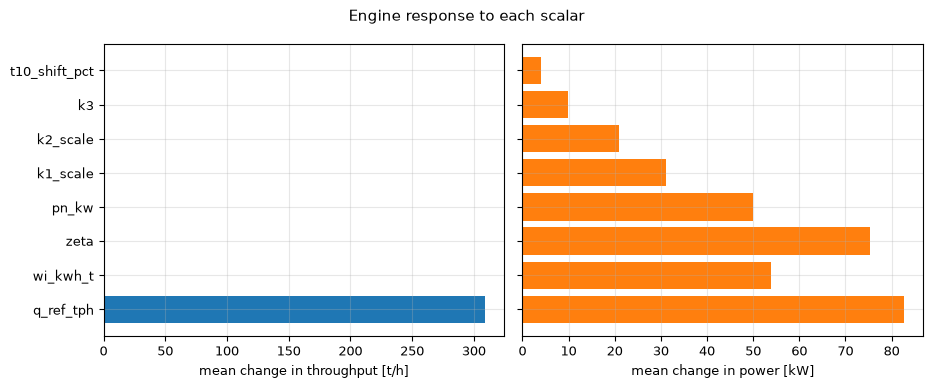

In [6]:

# The response of the engine to one prior standard deviation of each scalar
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.9), sharey=True)
labels = [p.name for p in cb.PRIORS]
axes[0].barh(labels, effect[:, 0], color="tab:blue")
axes[1].barh(labels, effect[:, 1], color="tab:orange")
axes[0].set_xlabel('mean change in throughput [t/h]')
axes[1].set_xlabel('mean change in power [kW]')
fig.suptitle('Engine response to each scalar')
fig.tight_layout()
plt.show()


Only one scalar moves the throughput: the capacity base `q_ref_tph` shifts it by 309 t/h for one prior standard deviation, and the other seven do not move it at all (0.0 t/h). All eight move the power: the capacity base (83 kW), `zeta` (75 kW) and `wi_kwh_t` (54 kW) at the top, then `pn_kw` (50 kW), `k1_scale` (31), `k2_scale` (21), `k3` (10) and `t10_shift_pct` (4). The figure does not say whether the data can tell the scalars apart: several scalars move the power in the same direction through the same product size, so they can compensate one another. It says what is necessary for a scalar to be learned, that it moves a measured output at all, and that the last two, `k3` and `t10_shift_pct` (10 and 4 kW), move the power by close to an order of magnitude less than the first three (54 to 83 kW). Notebook 02 of this topic measures the rest.

**Step 3, the prior predictive check.** Before a calibration looks at the surveys, the priors alone imply a distribution of engine outputs: draw the eight scalars from their priors (a normal around the nominal value, kept inside the prior's bounds, which `cb.log_prior` checks), run the engine at every draw on the ten surveys, and take the 10th and 90th percentiles per survey. A prior that is sensible produces a band that contains the measurements without being absurdly wide. The cell uses 200 draws, counts how many measured values fall inside their band and on which side the others fall, where the engine as shipped sits, and how wide the power band is against the measured spread.

In [7]:

# Prior predictive check: 200 draws of the scalars from their priors, the engine run at each, the 80
# percent band per survey
rng = np.random.default_rng(1)
draws = []
while len(draws) < 200:
    theta = centre.copy()
    theta[:cb.N_ENGINE] += sd * rng.standard_normal(cb.N_ENGINE)
    if np.isfinite(cb.log_prior(theta)):
        draws.append(theta)
runs = [[evaluate(op, cb.scalars_of(theta)) for op in ops] for theta in draws]
prior_tph = np.array([[r.throughput_tph for r in run] for run in runs])
prior_kw = np.array([[r.power_kw for r in run] for run in runs])
lo_t, hi_t = np.percentile(prior_tph, [10, 90], axis=0)
lo_k, hi_k = np.percentile(prior_kw, [10, 90], axis=0)
inside_t = np.sum((tph >= lo_t) & (tph <= hi_t))
inside_k = np.sum((kw >= lo_k) & (kw <= hi_k))
print(f"measured inside the prior 80 % band: {inside_t} of 10 for the throughput and {inside_k} of 10 for the power")
print(f"mean band width: {np.mean(hi_t - lo_t):.0f} t/h and {np.mean(hi_k - lo_k):.0f} kW")
# Where the engine as shipped and the measurements sit against the band, and its width against the measured spread
ship_t = np.sum((engine_tph >= lo_t) & (engine_tph <= hi_t))
ship_k = np.sum((engine_kw >= lo_k) & (engine_kw <= hi_k))
print(f"engine as shipped inside the band: {ship_t} of 10 for the throughput and {ship_k} of 10 for the power")
print(f"measured power below its band: {np.sum(kw < lo_k)} of 10 | above it: {np.sum(kw > hi_k)} of 10")
spread = kw.max() - kw.min()
print(f"power band width against the measured spread of {spread:.0f} kW: {np.mean(hi_k - lo_k) / spread:.2f} times")


measured inside the prior 80 % band: 9 of 10 for the throughput and 6 of 10 for the power
mean band width: 642 t/h and 313 kW
engine as shipped inside the band: 10 of 10 for the throughput and 10 of 10 for the power
measured power below its band: 4 of 10 | above it: 0 of 10
power band width against the measured spread of 168 kW: 1.86 times


The figure draws each survey's prior band as a grey bar, the measured value as a red dot and the engine as shipped as a black dash.

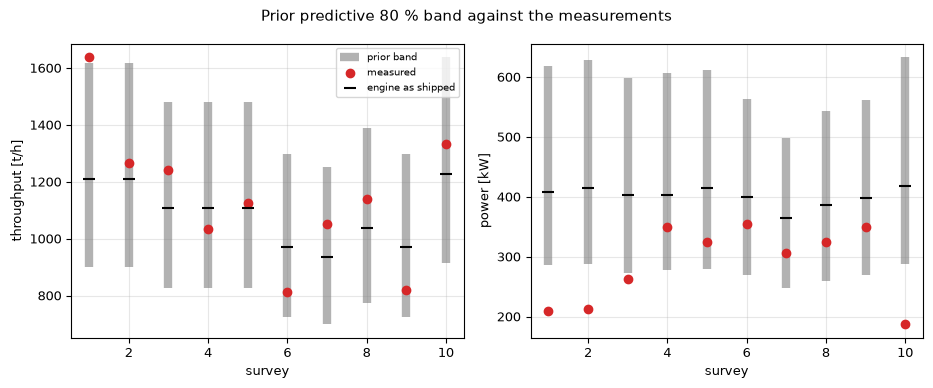

In [8]:

# The prior predictive band of each survey against the measured value
x = np.arange(1, len(ops) + 1)
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.9))
for ax, lo, hi, y, shipped_y, ylabel in ((axes[0], lo_t, hi_t, tph, engine_tph, 'throughput [t/h]'),
                                         (axes[1], lo_k, hi_k, kw, engine_kw, 'power [kW]')):
    ax.vlines(x, lo, hi, color="tab:grey", lw=6, alpha=0.6, label='prior band')
    ax.scatter(x, y, color="tab:red", zorder=3, label='measured')
    ax.scatter(x, shipped_y, color="black", marker="_", s=80, zorder=3, label='engine as shipped')
    ax.set_xlabel('survey')
    ax.set_ylabel(ylabel)
axes[0].legend(fontsize=7)
fig.suptitle('Prior predictive 80 % band against the measurements')
fig.tight_layout()
plt.show()


The prior band holds 9 of the 10 measured throughputs and 6 of the 10 measured powers, with a mean width of 642 t/h and 313 kW. The priors are therefore wide enough not to rule out most of what the plant did, which is what a weakly informative prior is for, and the power band is 1.86 times the measured spread of 168 kW, almost twice it, so the priors alone say little about which survey draws more. The engine as shipped, the black dashes, sits inside both bands on all ten surveys, as it must for priors centred on it. What falls outside is the measurement: four measured powers lie below their band and none above, because the priors are centred on an engine whose power is too high. The figure does not show whether the data pull the scalars toward a region that fits; that is what sampling the posterior does, and it is the next notebook.

**Step 4, the shape of what is left.** The engine at any scalar values is a smooth function of the setting and the feed size, and so is the part of the plant's behaviour that a physical model leaves out. A discrepancy term, in the form Kennedy and O'Hagan (2001) gave it, is a flexible function added to the model to carry that structured error, instead of forcing the scalars to absorb it. CrusherBayes uses its lowest order: a constant and one slope on the standardized setting and one on the standardized feed f80, per target. The cell regresses the residual of the shipped engine on exactly that plane, to see how much of the error has that shape.

In [9]:

# The residual of the shipped engine regressed on the standardized setting and f80, the form of the
# discrepancy
mu = np.array([css.mean(), f80.mean()])
scale = np.array([css.std(), f80.std()])
design = cb.design(css, f80, mu, scale)
fitted = {}
for name, y, engine_y in (("tph", tph, engine_tph), ("kW", kw, engine_kw)):
    resid = y - engine_y
    coef, *_ = np.linalg.lstsq(design, resid, rcond=None)
    r_squared = 1 - np.sum((resid - design @ coef) ** 2) / np.sum((resid - resid.mean()) ** 2)
    fitted[name] = (resid, design @ coef)
    print(f"{name:5s} residual sd {resid.std():6.1f}: constant {coef[0]:+7.1f}, setting {coef[1]:+7.1f}, "
          f"f80 {coef[2]:+7.1f} per standard deviation, R squared {r_squared:.2f}")


tph   residual sd  161.3: constant   +57.9, setting  +116.0, f80   +68.1 per standard deviation, R squared 0.45
kW    residual sd   69.8: constant  -113.1, setting   -64.5, f80    -5.5 per standard deviation, R squared 0.80


The figure draws, for each target, the residual of the shipped engine against the setting as red dots and the fitted plane evaluated at the same surveys as blue crosses.

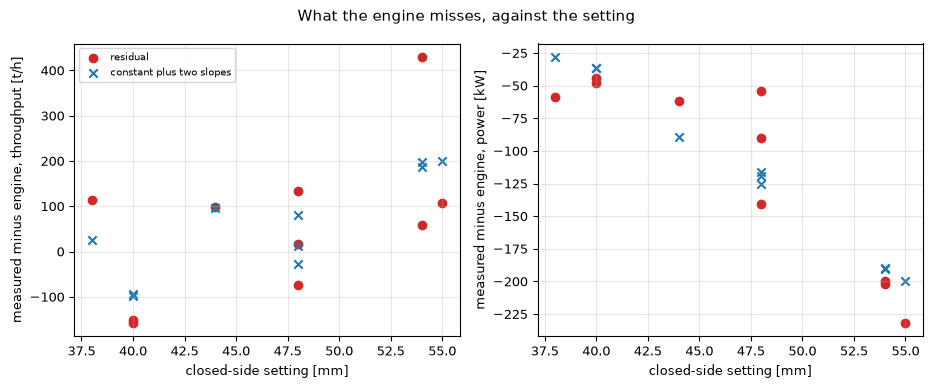

In [10]:

# The residual of the shipped engine against the setting, with the fitted discrepancy plane
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.9))
panels = (
    (axes[0], "tph", 'measured minus engine, throughput [t/h]'),
    (axes[1], "kW", 'measured minus engine, power [kW]'),
)
for ax, name, ylabel in panels:
    resid, plane = fitted[name]
    ax.scatter(css, resid, color="tab:red", label='residual')
    ax.scatter(css, plane, color="tab:blue", marker="x", label='constant plus two slopes')
    ax.set_xlabel('closed-side setting [mm]')
    ax.set_ylabel(ylabel)
axes[0].legend(fontsize=7)
fig.suptitle('What the engine misses, against the setting')
fig.tight_layout()
plt.show()


The plane accounts for 0.80 of the variance of the power residual and 0.45 of the throughput residual. On the power the setting slope is -64 kW per standard deviation, the feed slope is -6 kW and the constant is -113 kW, so almost all of the structured error is the setting: the engine misses the rise of the plant's power as the setting closes. On the throughput the slopes are +116 t/h for the setting and +68 t/h for the feed, a weaker and less clean pattern. A regression on ten points with three coefficients always fits some of the noise, so these R squared values are optimistic and are not the claim: the claim is only that the error has a form that a low-order function of the setting and the feed can carry, and that is the case for adding a discrepancy and for refitting it without each held-out survey, which the next two notebooks do.

## Results

**Answer:** the shipped engine leaves its power unexplained and its throughput nearly explained, only one of its eight scalars can move the throughput, and what is left over has the shape of a function of the setting. At its shipped values the engine has a MAPE of 11.55 percent on the throughput and 47.58 percent on the power, with the power +113 kW above the plant on average and flat between 365 and 419 kW where the plant runs from 187 to 355 kW. Moving each scalar by one prior standard deviation shifts the throughput by 309 t/h through the capacity base alone, while the other seven do not move it at all, and moves the power by up to 82.7 kW, also through the capacity base, with `zeta` next at 75.3 kW; all eight move the power. Drawn from their priors, the scalars give an 80 percent band that contains 9 of the 10 measured throughputs and 6 of the 10 measured powers, with mean widths of 642 t/h and 313 kW; the engine as shipped lies inside both bands on all ten surveys, and four measured powers fall below theirs. A plane in the setting and the feed accounts for 0.80 of the power residual (setting slope -64 kW per standard deviation) and 0.45 of the throughput residual, an in-sample figure on ten points that argues for a discrepancy term and proves nothing about out-of-sample skill.

## Summary

A calibration needs three things the engine already has or this notebook built: a model that runs fast enough to be called thousands of times, a set of unknowns with priors that are wide enough not to exclude the plant, and a clear picture of what the model cannot explain. The shipped engine explains the throughput and leaves the power flat; one scalar controls the first and all eight share the second, the capacity base first, several of them through the same product size; and the unexplained part follows the setting. The next notebook samples the posterior of the eight scalars and the noise on the surveys, and shows which of them the data move.

## References

- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919
- Kennedy, M. C., O'Hagan, A. (2001), Bayesian calibration of computer models, Journal of the Royal Statistical Society B 63(3), 425-464. https://doi.org/10.1111/1467-9868.00294